# Generate input file

This notebook is used for scripting part of the PFLOTRAN input file.

Contact: Chao Zeng, chao.zeng@pnnl.gov

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
from tqdm import tqdm
from shapely.geometry import Point

In [2]:
import os
import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(name)s - %(levelname)s: %(message)s')
import pickle

In [3]:
import sys
#sys.path.remove('/global/u1/z/zc727')
print(sys.path)
import geopandas as gpd

['/global/u1/z/zc727/HFR/notebooks', '/opt/nersc/pymon', '/global/common/software/nersc/pe/conda-envs/24.1.0/python-3.11/nersc-python/lib/python311.zip', '/global/common/software/nersc/pe/conda-envs/24.1.0/python-3.11/nersc-python/lib/python3.11', '/global/common/software/nersc/pe/conda-envs/24.1.0/python-3.11/nersc-python/lib/python3.11/lib-dynload', '', '/global/homes/z/zc727/.local/perlmutter/python-3.11/lib/python3.11/site-packages', '/global/common/software/nersc/pe/conda-envs/24.1.0/python-3.11/nersc-python/lib/python3.11/site-packages']


In [4]:
from shapely.geometry import Polygon, LineString, Point

In [5]:
#!pip install xarray

import xarray as xr
from scipy.spatial import cKDTree

In [6]:
from functools import partial
#!pip install geopandas
#!pip install geocube
from geocube.api.core import make_geocube
from geocube.rasterize import rasterize_points_griddata

In [8]:
fname_river_bc = "/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/boundary_conditions/river_bc"
fname_stage_bc = fname_river_bc + "/stage_2007-2019"
fname_temp_bc = fname_river_bc + "/temp_2007-2019"

data_dir = "/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/"
fname_WellScreen =  data_dir + "well_obs/HEIS_300A_AT_well_screen.csv"
#fname_centroid_df = data_dir + "pickle/hanford_mesh_100m-updated-centroid_df.p"
bnd_shp = data_dir + 'shapefile/boundary_poly_v5.shp'

In [9]:
watershed_bound = gpd.read_file(bnd_shp)

## region block

total number of file: 325


100%|██████████| 325/325 [00:00<00:00, 879.26it/s]


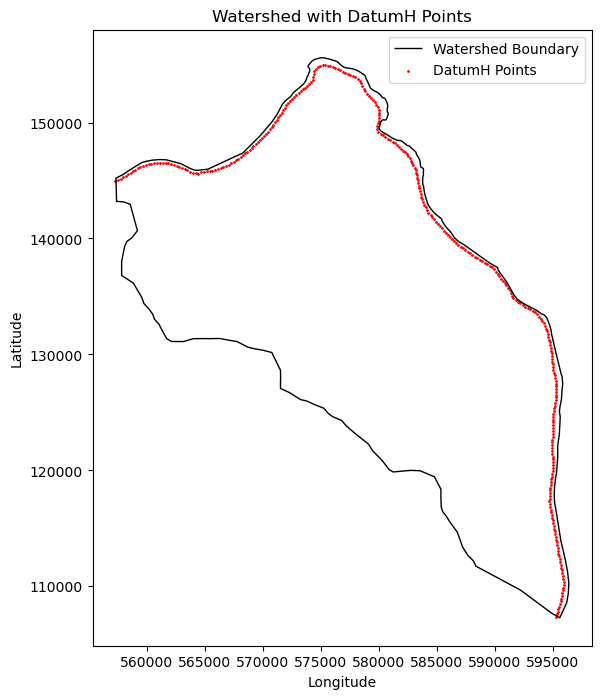

In [26]:
# display the location of DatumH points in the watershed

#Load the watershed shapefile into a GeoDataFrame
fname_DatumH_files = '/global/homes/z/zc727/HFR/data/stage_2007-2019/'+'DatumH_River_*.txt'
DatumH_files = glob.glob(fname_DatumH_files)
assert(len(DatumH_files) > 0),"No such files found in the specified directory."
print('total number of file: {}'.format(len(DatumH_files)))

coord_xy_list = []

for ifile in tqdm(DatumH_files[:]):   
    idf_1st_row = pd.read_table(ifile, sep=' ',header=None, nrows=1, engine='python')
    coord_xy = (idf_1st_row.iloc[0,1],idf_1st_row.iloc[0,2])
    coord_xy_list.append(coord_xy)

# Convert coord_xy_list to a GeoDataFrame
geometry = [Point(xy) for xy in coord_xy_list]
coordinates_gdf = gpd.GeoDataFrame(geometry=geometry, crs=watershed_bound.crs)  # Assuming WGS84

# Plotting
fig, ax = plt.subplots(figsize=(12, 8))

# Plot the watershed boundary
watershed_bound.boundary.plot(ax=ax, color='black', linewidth=1, label='Watershed Boundary')

# Plot the points
coordinates_gdf.plot(ax=ax, color='red', markersize=1, label='DatumH Points')

# Add labels and legend
ax.set_title('Watershed with DatumH Points')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.legend()

# Show the plot
plt.show()

In [27]:
flow_regions = [f'Flow_Mass1_{i}' for i in np.arange(35,360)]

In [28]:
flow_region_block = []
for i in np.arange(35,360):
    iregion = f'Flow_Mass1_{i}'
    idatum = f'DatumH_River_{i}.txt'
    igradient = f'Gradients_River_{i}.txt'
    itemp = f'Temp_River_{i}.txt'
    
    iblock = f'''
FLOW_CONDITION {iregion}
  INTERPOLATION LINEAR
  TYPE
    PRESSURE seepage
    TEMPERATURE dirichlet
  /
  DATUM file {os.path.join(fname_stage_bc, idatum)}
  PRESSURE 101325
  GRADIENT
    PRESSURE file {os.path.join(fname_stage_bc, igradient)}
  /
  TEMPERATURE file {os.path.join(fname_temp_bc, itemp)}
END
'''
    flow_region_block.append(iblock)

In [43]:
print(''.join(flow_region_block)) 


FLOW_CONDITION Flow_Mass1_35
  INTERPOLATION LINEAR
  TYPE
    PRESSURE seepage
    TEMPERATURE dirichlet
  /
  DATUM file /global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/boundary_conditions/river_bc/stage_2007-2019/DatumH_River_35.txt
  PRESSURE 101325
  GRADIENT
    PRESSURE file /global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/boundary_conditions/river_bc/stage_2007-2019/Gradients_River_35.txt
  /
  TEMPERATURE file /global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/boundary_conditions/river_bc/temp_2007-2019/Temp_River_35.txt
END

FLOW_CONDITION Flow_Mass1_36
  INTERPOLATION LINEAR
  TYPE
    PRESSURE seepage
    TEMPERATURE dirichlet
  /
  DATUM file /global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/boundary_conditions/river_bc/stage_2007-2019/DatumH_River_36.txt
  PRESSURE 101325
  GRADIENT
    PRESSURE file /global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/boundary_conditions/river_bc/stage_2007-2019/Gradients_River_36.txt
  /
  TEMPERATURE file /glob

### save to file

In [9]:
fname_pflotran_in = '../model_run/flow_condition.in'

In [10]:
with open(fname_pflotran_in, "w") as text_file:
    print(''.join(flow_region_block), file=text_file)

logging.info(f'Saved plotran.in file in: {fname_pflotran_in}')

NameError: name 'flow_region_block' is not defined

## Observation block

We need to use the relative depth below model surface to map the observation points because some of the piezometer/wells fall outside of the model domain.

In [37]:
well_screen = pd.read_csv(fname_WellScreen, index_col=0)

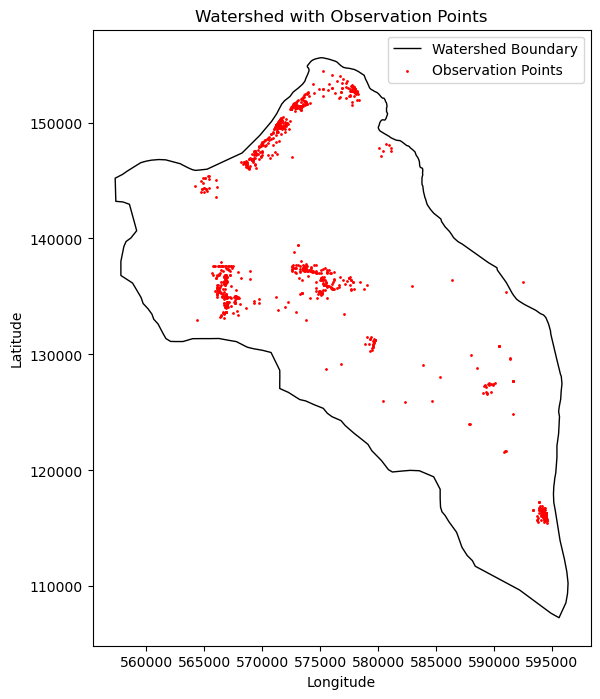

In [46]:
# Load well screen data
#fname_WellScreen = 'path/to/your/well_screen.csv'  # Update with your actual file path
#well_screen = pd.read_csv(fname_WellScreen, index_col=0)

# Extract coordinates from the well screen data
well_xy = list(zip(well_screen['Easting'], well_screen['Northing']))

# Convert well_xy list to a GeoDataFrame
geometry = [Point(xy) for xy in well_xy]
coordinates_gdf = gpd.GeoDataFrame(geometry=geometry, crs=watershed_bound.crs)

# Plotting
fig, ax = plt.subplots(figsize=(12, 8))

# Plot the watershed boundary
watershed_bound.boundary.plot(ax=ax, color='black', linewidth=1, label='Watershed Boundary')

# Plot the DatumH points
coordinates_gdf.plot(ax=ax, color='red', markersize=1, label='Observation Points')

# Add labels and legend
ax.set_title('Watershed with Observation Points')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.legend()

# Show the plot
plt.show()

In [29]:
fname_centroid_df = '/global/homes/z/zc727/HFR/mesh/hanford_100m-updated-matID_alluvium.p'
with open(fname_centroid_df, "rb") as f:
    centroid_df = pickle.load(f)

In [30]:
print(centroid_df.keys())

Index(['x', 'y', 'z', 'dem', 'cc', 'tf', 're', 'rlm', 'ra', 'ba', 'layer_ids',
       'mat_ids', 'river_idx'],
      dtype='object')


In [31]:
top_model_layer = centroid_df[centroid_df['layer_ids']==1].copy()

In [32]:
# add half thickness of the top layer to get surface elev.
top_model_layer['surface_z'] = top_model_layer['z'] + 0.05 

In [33]:
print(top_model_layer.keys())
print(np.shape(top_model_layer['y']))

Index(['x', 'y', 'z', 'dem', 'cc', 'tf', 're', 'rlm', 'ra', 'ba', 'layer_ids',
       'mat_ids', 'river_idx', 'surface_z'],
      dtype='object')
(29127,)


In [34]:
gdf = gpd.GeoDataFrame(top_model_layer, geometry=gpd.points_from_xy(top_model_layer['x'], top_model_layer['y']),
                      crs="EPSG:2856")

In [35]:
geo_grid = make_geocube(
    gdf,
    measurements=["surface_z"],
    resolution=(-10, 10),
    rasterize_function=partial(rasterize_points_griddata, method="cubic"),
)

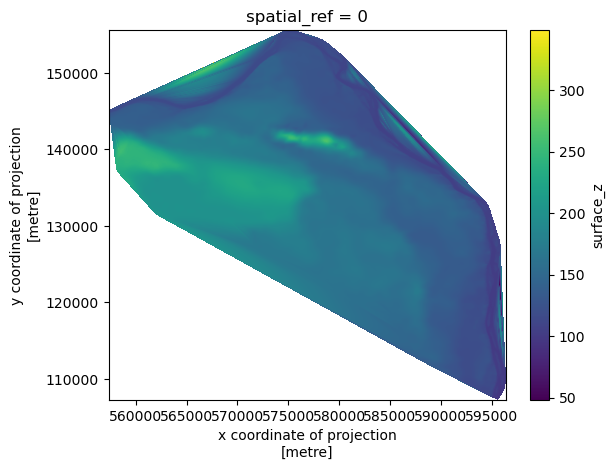

In [58]:
geo_grid.surface_z.plot.imshow()

In [36]:
geo_grid

<xarray.Dataset>
Dimensions:      (y: 4824, x: 3902)
Coordinates:
  * y            (y) float64 1.556e+05 1.556e+05 ... 1.073e+05 1.073e+05
  * x            (x) float64 5.573e+05 5.574e+05 ... 5.963e+05 5.964e+05
    spatial_ref  int64 0
Data variables:
    surface_z    (y, x) float64 nan nan nan nan nan nan ... nan nan nan nan nan

### Piezometers

Piezometers measure point values at certain depths.

In [47]:
well_screen['depth_to_topScreen'] = well_screen['CASING_ELEVATION'] - well_screen['SCREEN_ELEV_TOP']

In [48]:
piezometers = well_screen.iloc[:73, :].copy()     # why use data before 73??? first 73 data are piezometers well

In [49]:
# need to add 'z' to make it point pairs instead of 2D array
model_z = geo_grid.surface_z.interp(x=('z', piezometers.Easting), 
                                    y=('z', piezometers.Northing)).values

In [50]:
piezometers['model_z'] = model_z

In [51]:
piezometers

,WellName,Easting,Northing,CASING_ELEVATION,SCREEN_ELEV_TOP,SCREEN_ELEV_BOTTOM,depth_to_topScreen,model_z
Well_ID,,,,,,,,
iButton_B2_3,iButton_B2_8cm,594502.270,116179.490,105.570,105.490,NaN,0.080,105.749455
iButton_B2_4,iButton_B2_28cm,594502.270,116179.490,105.570,105.290,NaN,0.280,105.749455
iButton_B2_5,iButton_B2_48cm,594502.270,116179.490,105.570,105.090,NaN,0.480,105.749455
iButton_B2_6,iButton_B2_88cm,594502.270,116179.490,105.570,104.690,NaN,0.880,105.749455
RG3_T3_4,RG3_T3_4cm,594484.500,116245.100,105.600,105.560,NaN,0.040,105.603968
...,...,...,...,...,...,...,...,...
TM_M2_T_Avg(30),T10_104_44cm,594466.189,116312.337,104.051,103.411,NaN,0.640,106.324120
TM_M2_T_Avg(31),T10_104.5_50cm,594464.145,116311.153,104.441,103.731,NaN,0.710,106.533391
TM_M2_T_Avg(32),T10_104.5_67cm,594464.589,116310.421,104.427,103.567,NaN,0.860,106.501913


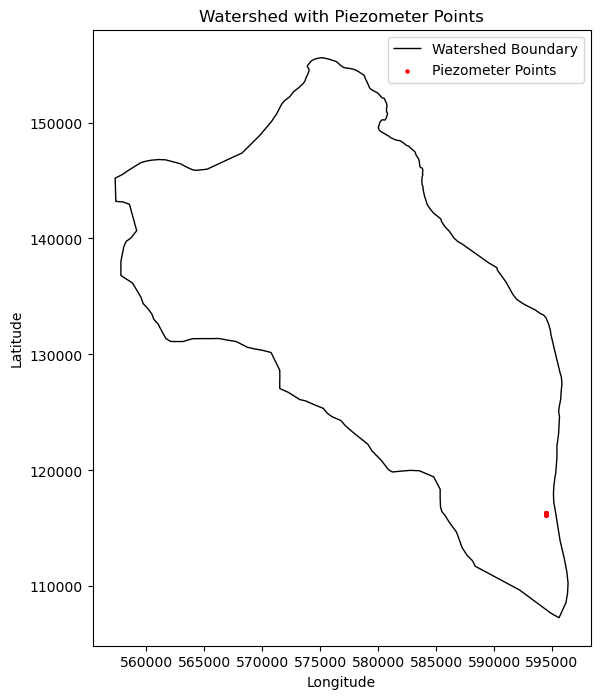

In [56]:
# Extract coordinates from the well screen data
well_xy = list(zip(piezometers['Easting'], piezometers['Northing']))

# Convert well_xy list to a GeoDataFrame
geometry = [Point(xy) for xy in well_xy]
coordinates_gdf = gpd.GeoDataFrame(geometry=geometry, crs=watershed_bound.crs)

# Plotting
fig, ax = plt.subplots(figsize=(12, 8))

# Plot the watershed boundary
watershed_bound.boundary.plot(ax=ax, color='black', linewidth=1, label='Watershed Boundary')

# Plot the DatumH points
coordinates_gdf.plot(ax=ax, color='red', markersize=5, label='Piezometer Points')

# Add labels and legend
ax.set_title('Watershed with Piezometer Points')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.legend()

# Show the plot
plt.show()

**write to input deck**

In [57]:
# the following piezometers are outside of model domain when running PF, why these well????
outlier_piezometers = ['RG3_T3_4cm', 'T7_104_53cm', 'T7_104.5_50cm', 'T8_104_60cm', 'T8_104.5_50cm', 'T8_105.5_46cm', 'T9_104_43.5cm', 
                       'T9_104_58cm', 'T9_104.5_50cm', 'T9_104.5_70cm', 'T9_105.5_47cm', 'T10_104_41cm', 'T10_104_44cm', 'T10_104.5_50cm',
                      'T10_104.5_67cm', 'T10_105.5_60cm', 'T10_105.5_72.5cm']

In [59]:
outlier_well =set(piezometers['WellName']).intersection(outlier_piezometers)
print(outlier_well)

{'T8_104.5_50cm', 'T8_104_60cm', 'T8_105.5_46cm', 'T9_104_58cm', 'T9_104.5_70cm', 'RG3_T3_4cm', 'T10_105.5_60cm', 'T10_104.5_67cm', 'T10_105.5_72.5cm', 'T9_104_43.5cm', 'T10_104_41cm', 'T7_104.5_50cm', 'T9_105.5_47cm', 'T7_104_53cm', 'T9_104.5_50cm', 'T10_104_44cm', 'T10_104.5_50cm'}


In [60]:
piezometers = piezometers[~piezometers['WellName'].isin(outlier_piezometers)]

In [61]:
print(len(piezometers.index))

56


In [79]:
region_block = []
observation_block = []
for i in piezometers.index:
    iname = piezometers.loc[i, 'WellName']
    x = piezometers.loc[i, 'Easting']
    y = piezometers.loc[i, 'Northing']
    z = piezometers.loc[i, 'model_z'] - piezometers.loc[i, 'depth_to_topScreen']
        
    iregion_block = f'''
  REGION {iname} 
    COORDINATE {x} {y} {z} 
  /    
'''
    region_block.append(iregion_block)
    
    iobs_block = f'''
  OBSERVATION
    REGION {iname}
    VELOCITY 
    AT_COORDINATE    
  / 
''' 
    observation_block.append(iobs_block)

In [33]:
print(''.join(region_block)) 


  REGION iButton_B2_8cm 
    COORDINATE 594502.27 116179.49 105.66945508110585 
  /    

  REGION iButton_B2_28cm 
    COORDINATE 594502.27 116179.49 105.46945508110586 
  /    

  REGION iButton_B2_48cm 
    COORDINATE 594502.27 116179.49 105.26945508110586 
  /    

  REGION iButton_B2_88cm 
    COORDINATE 594502.27 116179.49 104.86945508110585 
  /    

  REGION RG3_T3_24cm 
    COORDINATE 594484.5 116245.1 105.36396836567222 
  /    

  REGION RG3_T3_64cm 
    COORDINATE 594484.5 116245.1 104.96396836567222 
  /    

  REGION T1_104_50cm 
    COORDINATE 594485.77 116260.403 104.39036912099878 
  /    

  REGION T1_104_105cm 
    COORDINATE 594485.884 116259.905 103.84634244321023 
  /    

  REGION T1_104.5_45cm 
    COORDINATE 594482.274 116260.125 104.79141216569293 
  /    

  REGION T1_104.5_60cm 
    COORDINATE 594482.529 116259.589 104.6032780041053 
  /    

  REGION T1_105.5_53cm 
    COORDINATE 594477.897 116258.487 105.15621903842292 
  /    

  REGION T1_105.5_103.5cm 


In [49]:
print(''.join(observation_block)) 


  OBSERVATION
    REGION iButton_B2_8cm
    VELOCITY 
    AT_COORDINATE    
  / 

  OBSERVATION
    REGION iButton_B2_28cm
    VELOCITY 
    AT_COORDINATE    
  / 

  OBSERVATION
    REGION iButton_B2_48cm
    VELOCITY 
    AT_COORDINATE    
  / 

  OBSERVATION
    REGION iButton_B2_88cm
    VELOCITY 
    AT_COORDINATE    
  / 

  OBSERVATION
    REGION RG3_T3_24cm
    VELOCITY 
    AT_COORDINATE    
  / 

  OBSERVATION
    REGION RG3_T3_64cm
    VELOCITY 
    AT_COORDINATE    
  / 

  OBSERVATION
    REGION T1_104_50cm
    VELOCITY 
    AT_COORDINATE    
  / 

  OBSERVATION
    REGION T1_104_105cm
    VELOCITY 
    AT_COORDINATE    
  / 

  OBSERVATION
    REGION T1_104.5_45cm
    VELOCITY 
    AT_COORDINATE    
  / 

  OBSERVATION
    REGION T1_104.5_60cm
    VELOCITY 
    AT_COORDINATE    
  / 

  OBSERVATION
    REGION T1_105.5_53cm
    VELOCITY 
    AT_COORDINATE    
  / 

  OBSERVATION
    REGION T1_105.5_103.5cm
    VELOCITY 
    AT_COORDINATE    
  / 

  OBSERVATION
    REGION

In [80]:
with open("../model_run/piezometer_region_block.in", "w") as text_file:
    print(''.join(region_block), file=text_file)
with open("../model_run/piezometer_obs_block.in", "w") as text_file:
    print(''.join(observation_block), file=text_file)
# logging.info(f'Saved plotran.in file in: {fname_pflotran_in}')

### GW wells

In [62]:
wells = well_screen.iloc[73:, :].copy()

In [63]:
wells['model_z'] = geo_grid.surface_z.interp(x=('z', wells.Easting), 
                                    y=('z', wells.Northing)).values

In [64]:
wells['model_bottom'] = wells['model_z'] - 100 # the total thickness of model layers is 100 m

In [65]:
wells['screen_length'] = wells['SCREEN_ELEV_TOP'] - wells['SCREEN_ELEV_BOTTOM']

In [66]:
wells

,WellName,Easting,Northing,CASING_ELEVATION,SCREEN_ELEV_TOP,SCREEN_ELEV_BOTTOM,depth_to_topScreen,model_z,model_bottom,screen_length
Well_ID,,,,,,,,,,
A5018,399-1-1,594359.99,116588.84,115.834000,109.738000,92.974000,6.096000,111.256973,11.256973,16.764000
A5035,399-1-2,594082.38,116329.58,118.975000,111.355000,96.115000,7.620000,117.297656,17.297656,15.240000
A5040,399-1-7,594260.13,116335.07,118.558000,110.938000,95.698000,7.620000,115.162760,15.162760,15.240000
A5411,399-1-10A,594346.57,116733.99,114.895000,107.427400,102.855400,7.467600,110.842812,10.842812,4.572000
A5020,399-1-11,594109.84,116660.16,116.156000,108.353120,101.891360,7.802880,115.311081,15.311081,6.461760
...,...,...,...,...,...,...,...,...,...,...
C9454,399-1-83,594152.48,116427.40,114.791680,105.815320,104.255970,8.976360,115.793298,15.793298,1.559350
C9455,399-1-84,594174.47,116451.41,114.821080,100.309552,98.729484,14.511528,115.449615,15.449615,1.580068
C9456,399-1-85,594175.50,116451.42,114.736928,105.611216,104.051942,9.125712,115.440552,15.440552,1.559274


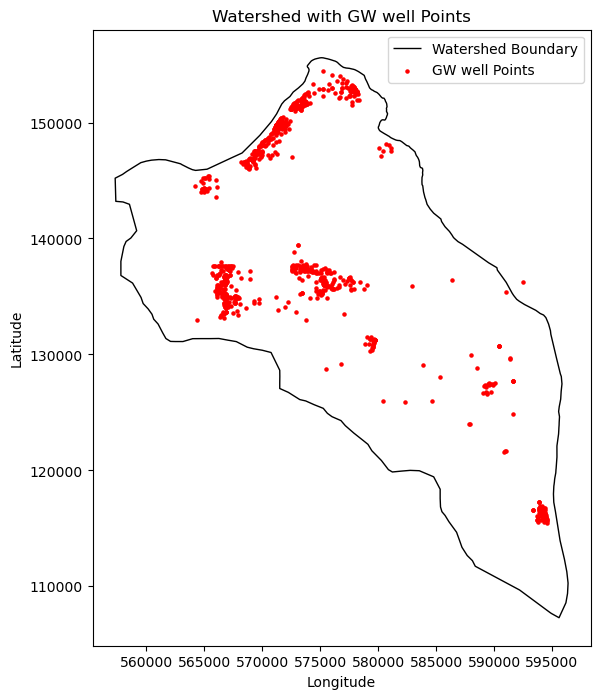

In [67]:
# Extract coordinates from the well screen data
well_xy = list(zip(wells['Easting'], wells['Northing']))

# Convert well_xy list to a GeoDataFrame
geometry = [Point(xy) for xy in well_xy]
coordinates_gdf = gpd.GeoDataFrame(geometry=geometry, crs=watershed_bound.crs)

# Plotting
fig, ax = plt.subplots(figsize=(12, 8))

# Plot the watershed boundary
watershed_bound.boundary.plot(ax=ax, color='black', linewidth=1, label='Watershed Boundary')

# Plot the DatumH points
coordinates_gdf.plot(ax=ax, color='red', markersize=5, label='GW well Points')

# Add labels and legend
ax.set_title('Watershed with GW well Points')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.legend()

# Show the plot
plt.show()

In [55]:
# wells.to_csv(data_dir + "well_obs/gw_wells_in_mesh_100m-updated.csv")

**write to input deck**

In [68]:
outlier_wells = ['299-E17-3', '199-K-117A', '199-K-119A', '699-37-47A', '299-E24-23', '699-95-48', '299-E27-155']

In [69]:
outlier_well =set(wells['WellName']).intersection(outlier_wells)
print(outlier_well)

{'199-K-119A', '299-E27-155', '299-E24-23', '299-E17-3', '699-37-47A', '699-95-48', '199-K-117A'}


In [65]:
wells = wells[~wells['WellName'].isin(outlier_wells)]

In [66]:
wells

,WellName,Easting,Northing,CASING_ELEVATION,SCREEN_ELEV_TOP,SCREEN_ELEV_BOTTOM,depth_to_topScreen,model_z,model_bottom,screen_length
Well_ID,,,,,,,,,,
A5018,399-1-1,594359.99,116588.84,115.834000,109.738000,92.974000,6.096000,111.256973,11.256973,16.764000
A5035,399-1-2,594082.38,116329.58,118.975000,111.355000,96.115000,7.620000,117.297656,17.297656,15.240000
A5040,399-1-7,594260.13,116335.07,118.558000,110.938000,95.698000,7.620000,115.162760,15.162760,15.240000
A5411,399-1-10A,594346.57,116733.99,114.895000,107.427400,102.855400,7.467600,110.842812,10.842812,4.572000
A5020,399-1-11,594109.84,116660.16,116.156000,108.353120,101.891360,7.802880,115.311081,15.311081,6.461760
...,...,...,...,...,...,...,...,...,...,...
C9454,399-1-83,594152.48,116427.40,114.791680,105.815320,104.255970,8.976360,115.793298,15.793298,1.559350
C9455,399-1-84,594174.47,116451.41,114.821080,100.309552,98.729484,14.511528,115.449615,15.449615,1.580068
C9456,399-1-85,594175.50,116451.42,114.736928,105.611216,104.051942,9.125712,115.440552,15.440552,1.559274


In [70]:
region_block = []
observation_block = []
for i in wells.index:
    name = wells.loc[i, 'WellName']
    x = wells.loc[i, 'Easting']
    y = wells.loc[i, 'Northing']
    z = wells.loc[i, 'model_z'] - wells.loc[i, 'depth_to_topScreen']
    
    # remove wells outside of watershed boundary
    if not watershed_bound.contains(Point(x,y))[0]:
        break
    
    if np.isnan(z):
        break

    screen_len = wells.loc[i, 'screen_length']
    dz = 2 # space well screens every 2 m
    model_bot = wells.loc[i, 'model_bottom']
    
    if screen_len > dz:
        nz = int(np.floor(screen_len / dz))
        for j in range(nz + 1):
            iname = 'Well_' + name + '_' + str(j + 1)
            iz = z - j*dz
            assert not np.isnan(iz)
            # see if the bottom obs point falls outside of domain
            if iz < model_bot:
                break
            # assert iz >= model_bot, "observation point falls out of model domain!"
            
            iregion_block = f'''
  REGION {iname} 
    COORDINATE {x} {y} {iz} 
  /    
'''
            region_block.append(iregion_block)
            
            # added AT_COORDINATE so that PF interpolate to the observation points
            iobs_block = f'''
  OBSERVATION
    REGION {iname}
    VELOCITY 
    AT_COORDINATE
  / 
''' 
            observation_block.append(iobs_block)
            
    else:
        z_bot = z - screen_len
        assert z_bot >= model_bot, "observation point falls out of model domain!"     # ?? should be <
        for j,iz in zip(range(2), [z, z_bot]):
            iname = 'Well_' + name + '_' + str(j + 1)
            
            iregion_block = f'''
  REGION {iname} 
    COORDINATE {x} {y} {iz} 
  /    
'''
            region_block.append(iregion_block)
    
            iobs_block = f'''
  OBSERVATION
    REGION {iname}
    VELOCITY 
    AT_COORDINATE    
  / 
''' 
            observation_block.append(iobs_block)        

In [72]:
print(len(region_block))
print(len(observation_block))

1622
1622


In [68]:
print(''.join(region_block)) 


  REGION Well_399-1-1_1 
    COORDINATE 594359.99 116588.84 105.16097337901664 
  /    

  REGION Well_399-1-1_2 
    COORDINATE 594359.99 116588.84 103.16097337901664 
  /    

  REGION Well_399-1-1_3 
    COORDINATE 594359.99 116588.84 101.16097337901664 
  /    

  REGION Well_399-1-1_4 
    COORDINATE 594359.99 116588.84 99.16097337901664 
  /    

  REGION Well_399-1-1_5 
    COORDINATE 594359.99 116588.84 97.16097337901664 
  /    

  REGION Well_399-1-1_6 
    COORDINATE 594359.99 116588.84 95.16097337901664 
  /    

  REGION Well_399-1-1_7 
    COORDINATE 594359.99 116588.84 93.16097337901664 
  /    

  REGION Well_399-1-1_8 
    COORDINATE 594359.99 116588.84 91.16097337901664 
  /    

  REGION Well_399-1-1_9 
    COORDINATE 594359.99 116588.84 89.16097337901664 
  /    

  REGION Well_399-1-2_1 
    COORDINATE 594082.38 116329.58 109.67765576057056 
  /    

  REGION Well_399-1-2_2 
    COORDINATE 594082.38 116329.58 107.67765576057056 
  /    

  REGION Well_399-1-2_3 
 

In [69]:
print(''.join(observation_block)) 


  OBSERVATION
    REGION Well_399-1-1_1
    VELOCITY 
    AT_COORDINATE
  / 

  OBSERVATION
    REGION Well_399-1-1_2
    VELOCITY 
    AT_COORDINATE
  / 

  OBSERVATION
    REGION Well_399-1-1_3
    VELOCITY 
    AT_COORDINATE
  / 

  OBSERVATION
    REGION Well_399-1-1_4
    VELOCITY 
    AT_COORDINATE
  / 

  OBSERVATION
    REGION Well_399-1-1_5
    VELOCITY 
    AT_COORDINATE
  / 

  OBSERVATION
    REGION Well_399-1-1_6
    VELOCITY 
    AT_COORDINATE
  / 

  OBSERVATION
    REGION Well_399-1-1_7
    VELOCITY 
    AT_COORDINATE
  / 

  OBSERVATION
    REGION Well_399-1-1_8
    VELOCITY 
    AT_COORDINATE
  / 

  OBSERVATION
    REGION Well_399-1-1_9
    VELOCITY 
    AT_COORDINATE
  / 

  OBSERVATION
    REGION Well_399-1-2_1
    VELOCITY 
    AT_COORDINATE
  / 

  OBSERVATION
    REGION Well_399-1-2_2
    VELOCITY 
    AT_COORDINATE
  / 

  OBSERVATION
    REGION Well_399-1-2_3
    VELOCITY 
    AT_COORDINATE
  / 

  OBSERVATION
    REGION Well_399-1-2_4
    VELOCITY 
    AT_CO

In [70]:
with open("../model_run/well_region_block.in", "w") as text_file:
    print(''.join(region_block), file=text_file)
with open("../model_run/well_obs_block.in", "w") as text_file:
    print(''.join(observation_block), file=text_file)
# logging.info(f'Saved plotran.in file in: {fname_pflotran_in}')

## permeability HDF5

In [19]:
## screen permeability data, remove data outside of model domain

filepath = '/global/homes/z/zc727/HFR/model_run/data_from_USGS.csv'

perm_df = pd.read_csv(filepath)

# Remove points that are higher or lower than the domain region's depth
perm_df1 = perm_df[perm_df['depth_below_river_m'] <= 101]  # Domain depth 100, 101 for interpolation

# Create a GeoDataFrame from the filtered DataFrame
geometry = [Point(xy) for xy in zip(perm_df1.X_ESRI_102349, perm_df1.Y_ESRI_102349)]
perm_gdf1 = gpd.GeoDataFrame(perm_df1, geometry=geometry)

# Ensure the CRS of the GeoDataFrame matches the watershed boundary
perm_gdf1 = perm_gdf1.set_crs(watershed_bound.crs, allow_override=True)

# Perform spatial join to keep only the points within the watershed boundary
perm_within_watershed = gpd.sjoin(perm_gdf1, watershed_bound, predicate='within')

# Interpolate surface_z values and add them to the DataFrame
# Ensure `geo_grid` and its method `surface_z.interp` are defined and accessible
#perm_within_watershed['model_z'] = geo_grid.surface_z.interp(
#    x=('z', perm_within_watershed.X_ESRI_102349), 
#    y=('z', perm_within_watershed.Y_ESRI_102349)
#).values

In [22]:
## get the Z coordinate of the permeability data points
# since geo_grid has different dimension of X and Y, use advanved algorithm to interpolate 'model_z' for points near watershed boundary.
# Extract coordinates and convert to 2D grid
x_coords = geo_grid.coords['x'].values
y_coords = geo_grid.coords['y'].values
surface_z_grid = geo_grid['surface_z'].values

# Verify sizes
print(f"x_coords size: {x_coords.size}, y_coords size: {y_coords.size}")
print(f"surface_z_grid shape: {surface_z_grid.shape}")

if x_coords.size != surface_z_grid.shape[1] or y_coords.size != surface_z_grid.shape[0]:
    raise ValueError("Mismatch between coordinate size and grid shape.")
    
# Generate interpolation grid
X, Y = np.meshgrid(x_coords, y_coords)
x_flattened = X.flatten()
y_flattened = Y.flatten()
z_flattened = surface_z_grid.flatten()  

# Nearest-neighbor interpolation function
def interpolate_nearest(x, y, z, xi, yi):
    tree = cKDTree(np.c_[x, y])
    _, idx = tree.query(np.c_[xi, yi], k=1)
    return z[idx]

# Generate model_z using nearest neighbor interpolation
perm_within_watershed['model_z'] = interpolate_nearest(x_flattened, y_flattened, z_flattened, 
                                                       perm_within_watershed.X_ESRI_102349, 
                                                       perm_within_watershed.Y_ESRI_102349)

# Fill remaining NaNs if necessary using ffill and bfill methods
perm_within_watershed['model_z'] = perm_within_watershed['model_z'].ffill().bfill()

# Check the number of NaNs remaining
print(perm_within_watershed['model_z'].isna().sum())

perm_within_watershed['Z'] = perm_within_watershed['model_z']-perm_within_watershed['depth_below_river_m']    # real elevation of permeability points

x_coords size: 3902, y_coords size: 4824
surface_z_grid shape: (4824, 3902)
0


## assign material ID to permeability data

In [23]:
## material ID assignment for the permeability data

import numpy as np
import pandas as pd
import rasterio
from tqdm import tqdm

# Directories and file names
bigdata_dir = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/'
fname_dem = bigdata_dir + 'DEM/topobathymetry_20200312_10m.tif'
fname_hanford_basal = bigdata_dir + 'DEM/hanford_basal.asc'
fname_ringolde_basal = bigdata_dir + 'DEM/ringolde_basal.asc'
fname_basalt_basal = bigdata_dir + 'DEM/basalt_basal.asc'
fname_ringoldlm_basal = bigdata_dir + 'DEM/ringoldlm_basal.asc'
fname_ringolda_basal = bigdata_dir + 'DEM/ringolda_basal.asc'
fname_coldcreek_basal = bigdata_dir + 'DEM/coldcreek_basal.asc'
fname_taylorflats_basal = bigdata_dir + 'DEM/taylorflats_basal.asc'

# Convert log10perm_md in CSV into m^2
conversion_factor = 9.869233e-16  # from md to m^2
perm_within_watershed['perm'] = 10**perm_within_watershed['log10perm_md'] * conversion_factor

# Extract coordinates
perm_xy = np.column_stack((perm_within_watershed['X_ESRI_102349'], perm_within_watershed['Y_ESRI_102349']))

# Sample raster data at the coordinates
def sample_raster(fname, points):
    with rasterio.open(fname) as ras:
        values = [val[0] for val in ras.sample(points)]
    return values

# Sample DEM and other raster layers
idx_dem = sample_raster(fname_dem, perm_xy)
idx_cc = sample_raster(fname_coldcreek_basal, perm_xy)
idx_tf = sample_raster(fname_taylorflats_basal, perm_xy)
idx_re = sample_raster(fname_ringolde_basal, perm_xy)
idx_rlm = sample_raster(fname_ringoldlm_basal, perm_xy)
idx_ra = sample_raster(fname_ringolda_basal, perm_xy)
idx_ba = sample_raster(fname_basalt_basal, perm_xy)

# Add sampled data to the DataFrame
perm_within_watershed['dem'] = idx_dem
perm_within_watershed['cc'] = idx_cc
perm_within_watershed['tf'] = idx_tf
perm_within_watershed['re'] = idx_re
perm_within_watershed['rlm'] = idx_rlm
perm_within_watershed['ra'] = idx_ra
perm_within_watershed['ba'] = idx_ba

# Mapping material labels to IDs
material_list = {'dem': 1, 'cc': 2, 'tf': 3, 're': 4, 'rlm': 5, 'ra': 6, 'ba': 9}

# Calculate material IDs based on depth
def assign_material_id(row):
    layers = ['dem', 'cc', 'tf', 're', 'rlm', 'ra', 'ba']
    lst = row['Z'] - row[layers]
    if all(lst > 0):
        return 1  # above all layers
    elif not any(lst > 0):
        return 9  # below all layers
    else:
        return material_list[lst[lst < 0].index[-1]]  # in between layers

# Apply material IDs assignment
perm_within_watershed['mat_ids'] = perm_within_watershed.apply(assign_material_id, axis=1)

# Update material IDs where depth_below_river_m < 1
perm_within_watershed.loc[perm_within_watershed['depth_below_river_m'] < 1, 'mat_ids'] = 10

# Print the first few rows to verify
print(perm_within_watershed.head())

    X_utm11N_m   Y_utm11N_m  X_ESRI_102349  Y_ESRI_102349   longitude  \
0  307201.7598  5178023.442    574658.1703    155472.2121 -119.523234   
1  307424.9263  5178023.442    574881.0853    155482.1290 -119.520317   
2  307648.0928  5178023.442    575104.0006    155492.0460 -119.517399   
3  307871.2593  5178023.442    575326.9161    155501.9629 -119.514481   
4  308094.4257  5178023.442    575549.8318    155511.8798 -119.511563   

    latitude  depth_below_river_m  elevation_m  log10EC_uScm  log10perm_md  \
0  46.727937                1.177   111.452150      2.472559      0.257881   
1  46.728001                1.177   106.674166      2.804265     -1.022014   
2  46.728065                1.177   112.204271      2.598523     -0.957576   
3  46.728130                1.177   109.169390      2.322206      0.833402   
4  46.728194                1.177   115.087221      2.514823     -0.359128   

   ...           Z          perm         dem          cc          tf  \
0  ...  129.996179  

In [24]:
print(perm_within_watershed[perm_within_watershed['mat_ids']==10].index)   # check if any permeability data within alluvium layer (ID=10)

Index([], dtype='int64')


In [26]:
with open("/global/homes/z/zc727/HFR/data/perm_within_watershed.p", 'wb') as f:
    pickle.dump(perm_within_watershed, f, protocol=-1)

## plot the permeability data

In [31]:
print(perm_within_watershed.index)

Index([    0,     1,     2,     3,     4,     5,     6,     7,     8,     9,
       ...
       16973, 16974, 16975, 16976, 16977, 16978, 16979, 16980, 16981, 16982],
      dtype='int64', length=16371)


In [1]:
import matplotlib.pyplot as plt
# Scatter plot
plt.figure(figsize=(10, 6))

# original perm data
perm_old = {
    1: 7.368421e-09, 2: 1.052632e-10, 3: 1.052632e-12, 4: 4.210526e-11, 
    5: 1.052632e-12, 6: 1.052632e-12, 9: 1.052632e-15, 10: 4.65e-13
}
perm_old_ids = list(perm_old.keys())
perm_old_values = list(perm_old.values())

# Plot perm_values as scatter points with respect to mat_ids
plt.scatter(perm_within_watershed['mat_ids'], perm_within_watershed['perm'], 
            color='blue', s=100, alpha=0.6, edgecolors='w', linewidth=0.5)

plt.scatter(perm_old_ids,perm_old_values,color='red',s=100,alpha=0.6,linewidth=0.5)

# Adding title and labels
plt.title('Perm Values vs. Mat IDs')
plt.xlabel('Mat IDs')
plt.ylabel('Perm Values[m2]')
plt.yscale('log')

all_perm_values = np.concatenate((perm_within_watershed['perm'].values,perm_old_values))
y_min = np.min(all_perm_values)
y_max = np.max(all_perm_values)

plt.ylim(y_min, y_max)

# Customize tick marks
#plt.xticks(rotation=45)
#plt.yticks(np.arange(0, 0.6, step=0.1))

# Add grid lines
plt.grid(True)

plt.legend(['USGS data','old data'])

# Show plot
plt.show()

NameError: name 'perm_within_watershed' is not defined

<Figure size 1000x600 with 0 Axes>

## interpolate permeability data into cell centroid

In [41]:
#import numpy as np
#import pandas as pd
from sklearn.neighbors import NearestNeighbors

# Find unique mat_ids
unique_mat_ids = perm_within_watershed['mat_ids'].unique()

# Function to interpolate and assign permeability values based on mat_ids
def interpolate_and_assign(mat_id):
    # Filter the data based on mat_id
    perm_data = perm_within_watershed[perm_within_watershed['mat_ids'] == mat_id]
    centroid_data = centroid_df[(centroid_df['mat_ids'] == mat_id) & (centroid_df['river_idx'] == True)]  # cell in river bed and with same mat_ids
    
    if not perm_data.empty and not centroid_data.empty:
        # Extract coordinates and permeability values
        perm_points = perm_data[['X_ESRI_102349', 'Y_ESRI_102349', 'Z']].values
        perm_values = perm_data['perm'].values
        log10perm_values = np.log10(perm_values)  # normalized to log10 base for better interpolation
        
        centroid_points = centroid_data[['x', 'y', 'z']].values
        
        # Initialize the NearestNeighbors object
        nbrs = NearestNeighbors(n_neighbors=3, algorithm='auto').fit(perm_points)
        
        # Find the nearest neighbors
        distances, indices = nbrs.kneighbors(centroid_points)
        
        # Weight the neighboring points' permeability values using the inverse distance weighting method
        interpolated_values = []
        for i in range(len(distances)):
            nearest_perms = log10perm_values[indices[i]]
            if np.any(distances[i] == 0):
                interpolated_values.append(nearest_perms[distances[i] == 0][0])
            else:
                weights = 1 / distances[i]
                interpolated_value = np.sum(weights * nearest_perms) / np.sum(weights)
                interpolated_values.append(interpolated_value)
        
        # Assign the interpolated values to centroid_df and convert back to 10^X scale
        centroid_df.loc[(centroid_df['mat_ids'] == mat_id) & (centroid_df['river_idx'] == True), 'perm_value'] = 10**np.array(interpolated_values)

# Initialize the perm column in centroid_df
centroid_df['perm_value'] = np.nan

# Interpolate and assign values for each unique mat_id
for mat_id in unique_mat_ids:
    interpolate_and_assign(mat_id)
    
# Original perm data for different layers (XY), Z is 10 times smaller for layer <= 9
perm_list = {
    1: 7.368421e-09, 2: 1.052632e-10, 3: 1.052632e-12, 4: 4.210526e-11, 
    5: 1.052632e-12, 6: 1.052632e-12, 9: 1.052632e-15, 10: 4.65e-13
}

# Assign perm value from perm_list to cells where river_idx is False based on their mat_ids
for mat_id, perm_val in perm_list.items():
    centroid_df.loc[(centroid_df['river_idx'] == False) & (centroid_df['mat_ids'] == mat_id), 'perm_value'] = perm_val

# Assign default perm value for NaN entries in perm_value where mat_ids == 10 and river_idx == True
centroid_df.loc[(centroid_df['mat_ids'] == 10) & (centroid_df['river_idx'] == True) & centroid_df['perm_value'].isna(), 'perm_value'] = perm_list[10]

# Print the first few rows to verify
print(centroid_df.head())

# Verify if interpolation worked correctly for different mat_ids
print(centroid_df.groupby('mat_ids')['perm_value'].describe())

               x              y           z         dem          cc  \
0  558454.229256  136693.840000  233.104122  228.606293  168.256302   
1  580508.238583  150448.245059  111.022571  111.108299  111.052498   
2  559932.654108  134754.205486  220.522968  214.780502  167.023102   
3  580575.455244  151015.296124  111.158507  110.878098  110.878098   
4  580653.188092  150675.546719  111.115299  110.869904  110.869904   

           tf          re         rlm         ra         ba  layer_ids  \
0  168.256302  168.256302   82.822807  82.822807  82.822807          1   
1  111.108299  109.727997  103.885201  31.682840  31.682840          1   
2  167.023102  167.023102   74.528709  48.215752 -16.753330          1   
3  110.878098  109.727997  103.776199  36.040798  36.040798          1   
4  110.869904  109.727997  103.723503  34.346680  34.346680          1   

   mat_ids  river_idx    perm_value  
0        1      False  7.368421e-09  
1       10       True  4.650000e-13  
2        1    

In [42]:
print(centroid_df['perm_value'].isna())   # check if any NaN perm_value

# print minimum permeability value and layer
min_perm_value = np.min(centroid_df['perm_value'])
min_perm_layer = centroid_df.loc[centroid_df['perm_value'] == min_perm_value, 'mat_ids'].values[0]
print('Minimum permeability: {0} in layer {1}'.format(min_perm_value, min_perm_layer))

# print maximum permeability value and layer
max_perm_value = np.max(centroid_df['perm_value'])
max_perm_layer = centroid_df.loc[centroid_df['perm_value'] == max_perm_value, 'mat_ids'].values[0]
print('Maximum permeability: {0} in layer {1}'.format(max_perm_value, max_perm_layer))

0         False
1         False
2         False
3         False
4         False
          ...  
902932    False
902933    False
902934    False
902935    False
902936    False
Name: perm_value, Length: 902937, dtype: bool
Minimum permeability: 6.03898807068881e-18 in layer 9
Maximum permeability: 7.368421e-09 in layer 1


In [44]:
with open("/global/homes/z/zc727/HFR/data/centroid_perm_df.p", 'wb') as f:
    pickle.dump(centroid_df, f, protocol=-1)

## output the .h5 file

In [104]:
#import numpy as np
#import pandas as pd
from h5py import File
#import os

# Define the mapping of mat_ids to filenames
mat_id_to_filename = {
    1: 'hanford', 
    2: 'cold_creek', 
    3: 'taylor_flats', 
    4: 'ringold_e', 
    5: 'ringold_lm', 
    6: 'ringold_a', 
    9: 'basalt', 
    10: 'alluvium'
}

# File path to save the .h5 data
file_path = '/global/homes/z/zc727/HFR/data/'

cell_ID_list = []
permX_list = []
permY_list = []
permZ_list = []

# Combine data from all mat_ids
for mat_id, filename in mat_id_to_filename.items():
    # Find the cell ID and ensure it has the 'i4' dtype
    cell_ID = np.array(centroid_df[centroid_df['mat_ids'] == mat_id].index.tolist(), dtype='i4') + 1  # starting from 1, rather than 0
    
    # Find the corresponding perm_values
    permX = centroid_df.loc[centroid_df['mat_ids'] == mat_id, 'perm_value'].tolist()
    permY = permX
    permZ = [val if mat_id == 10 else 0.1 * val for val in permX]
    
    cell_ID_list.extend(cell_ID)
    permX_list.extend(permX)
    permY_list.extend(permY)
    permZ_list.extend(permZ)

# Define the output HDF5 filename
output_file = f'{file_path}perm_data.h5'

# Remove the file if it exists to avoid file open conflicts automatically
if os.path.exists(output_file):
    os.remove(output_file)

# Save to HDF5 using h5py
with File(output_file, 'w') as h5file:
    h5file.create_dataset('Cell Ids', data=np.array(cell_ID_list, dtype='i4'))
    h5file.create_dataset('perm_meanX', data=np.array(permX_list, dtype='f8'))
    h5file.create_dataset('perm_meanY', data=np.array(permY_list, dtype='f8'))
    h5file.create_dataset('perm_meanZ', data=np.array(permZ_list, dtype='f8'))

print(f'Saved data to {output_file}')


Saved data to /global/homes/z/zc727/HFR/data/perm_data.h5


In [97]:
print(cell_ID)
print(np.shape(centroid_df[centroid_df['mat_ids'] == 10]))

[     2      4      5 ... 142673 142791 142792]
(97380, 14)


In [45]:
print(np.shape(centroid_df[centroid_df['mat_ids'] == mat_id].index.tolist()))

(97380,)
